In [13]:
# 08_imbalance_handling.ipynb

#  CELL 1: Setup
from __future__ import annotations

import json
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

OUTPUT_DIR = Path("./data/processed")
MODEL_DIR = Path("./models")
RESULT_DIR = Path("./results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

torch.manual_seed(42)
np.random.seed(42)
IMG_SIZE = 224

Device: cuda


In [14]:
#  CELL 2: Transforms  
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])



In [15]:
# ==================== CELL 3: Inlined Dataset + Model Classes ====================
EXCLUDE_COLS = {"ID", "has_cad", "max_stenosis", "num_diseased_vessels"}

def feature_columns(clinical_df):
    return [c for c in clinical_df.columns if c not in EXCLUDE_COLS]


class AngioCADDataset(Dataset):
    def __init__(self, patient_df, frames_df, clinical_df, transform=None,
                 aggregate="mean"):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.clinical = clinical_df.set_index("ID")
        self.transform = transform
        self.aggregate = aggregate
        self.feature_cols = feature_columns(clinical_df)

    def __len__(self):
        return len(self.patients)

    def _load_frames(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        tensors = []
        for path in subset["path"].tolist():
            try:
                img = Image.open(path).convert("RGB")
                tensors.append(self.transform(img) if self.transform
                               else transforms.ToTensor()(img))
            except Exception:
                continue
        return tensors

    def _aggregate(self, tensors):
        if not tensors:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE)
        stack = torch.stack(tensors)
        return stack.max(dim=0).values if self.aggregate == "max" else stack.mean(dim=0)

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        img = self._aggregate(self._load_frames(pid))
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, torch.from_numpy(clinical), label


class ImageEncoder(nn.Module):
    def __init__(self, out_dim=256, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.proj = nn.Sequential(
            nn.Linear(feat_dim, out_dim), nn.ReLU(inplace=True), nn.Dropout(0.3),
        )
    def forward(self, x):
        return self.proj(self.backbone(x))


class ClinicalEncoder(nn.Module):
    def __init__(self, in_dim, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, out_dim), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)


class FusionModel(nn.Module):
    def __init__(self, clinical_dim, num_classes=2):
        super().__init__()
        self.img_enc = ImageEncoder(out_dim=256)
        self.clin_enc = ClinicalEncoder(clinical_dim, out_dim=128)
        self.classifier = nn.Sequential(
            nn.Linear(256 + 128, 128), nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )
    def forward(self, image, clinical):
        return self.classifier(torch.cat([self.img_enc(image), self.clin_enc(clinical)], dim=1))



In [16]:
# ==================== CELL 4: Focal Loss ====================
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, weight=None):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
        if weight is not None:
            self.register_buffer("weight", weight)
        else:
            self.weight = None
    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets,
                                         weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1.0 - pt) ** self.gamma * ce).mean()



In [ ]:
# ==================== CELL 5: Training Helpers ====================
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    for image, clinical, y in loader:
        image = image.to(device)
        clinical = clinical.to(device)
        y = y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(image, clinical), y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * y.size(0)
    return running_loss / len(loader.dataset)


def evaluate(model, loader, device):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for image, clinical, y in loader:
            image = image.to(device)
            clinical = clinical.to(device)
            logits = model(image, clinical)
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.append(logits.argmax(dim=1).cpu().numpy())
            labels.append(y.numpy())
    y_true = np.concatenate(labels)
    y_pred = np.concatenate(preds)
    y_prob = np.concatenate(probs)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "auc": float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) > 1 else 0.5,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
    }



In [18]:

# ==================== CELL 6: Load Data ====================
clinical_df = pd.read_csv(OUTPUT_DIR / "clinical_features_merged.csv")
frames_df = pd.read_csv(OUTPUT_DIR / "frames_index.csv")
frames_df["ID"] = frames_df["ID"].astype(str)

with open(OUTPUT_DIR / "splits.json") as f:
    splits = json.load(f)
with open(OUTPUT_DIR / "class_weights.json") as f:
    class_weights = json.load(f)

train_df = clinical_df[clinical_df["ID"].isin(splits["train"])]
val_df = clinical_df[clinical_df["ID"].isin(splits["val"])]
test_df = clinical_df[clinical_df["ID"].isin(splits["test"])]

train_ds = AngioCADDataset(train_df, frames_df, clinical_df, transform=train_tfms)
val_ds = AngioCADDataset(val_df, frames_df, clinical_df, transform=eval_tfms)
test_ds = AngioCADDataset(test_df, frames_df, clinical_df, transform=eval_tfms)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

clinical_dim = len(train_ds.feature_cols)
weight_tensor = torch.tensor([class_weights["0"], class_weights["1"]],
                             dtype=torch.float32).to(DEVICE)



EXPERIMENT: Cross-Entropy (Weighted)
Epoch 01 | Loss: 0.6302 | Val AUC: 0.7389
Epoch 02 | Loss: 0.5266 | Val AUC: 0.6889
Epoch 03 | Loss: 0.5656 | Val AUC: 0.7500
Epoch 04 | Loss: 0.4718 | Val AUC: 0.8306
Epoch 05 | Loss: 0.4431 | Val AUC: 0.7750
Epoch 06 | Loss: 0.4090 | Val AUC: 0.7500
Epoch 07 | Loss: 0.4441 | Val AUC: 0.7417
Epoch 08 | Loss: 0.3877 | Val AUC: 0.7639
Epoch 09 | Loss: 0.3291 | Val AUC: 0.7917
Early stopping at epoch 9

Cross-Entropy Test Metrics:
  accuracy  : 0.6316
  auc       : 0.8156
  f1        : 0.7021
  precision : 0.9706
  recall    : 0.5500

FOCAL LOSS: Loading from Notebook 05 checkpoint
Focal Loss Test Metrics:
  accuracy  : 0.7763
  auc       : 0.8510
  f1        : 0.8468
  precision : 0.9216
  recall    : 0.7833

LOSS FUNCTION COMPARISON (Test Set)
                      Loss  accuracy    auc     f1  precision  recall
  Cross-Entropy (Weighted)    0.6316 0.8156 0.7021     0.9706  0.5500
Focal Loss (α=0.25, γ=2.0)    0.7763 0.8510 0.8468     0.9216  0.7833

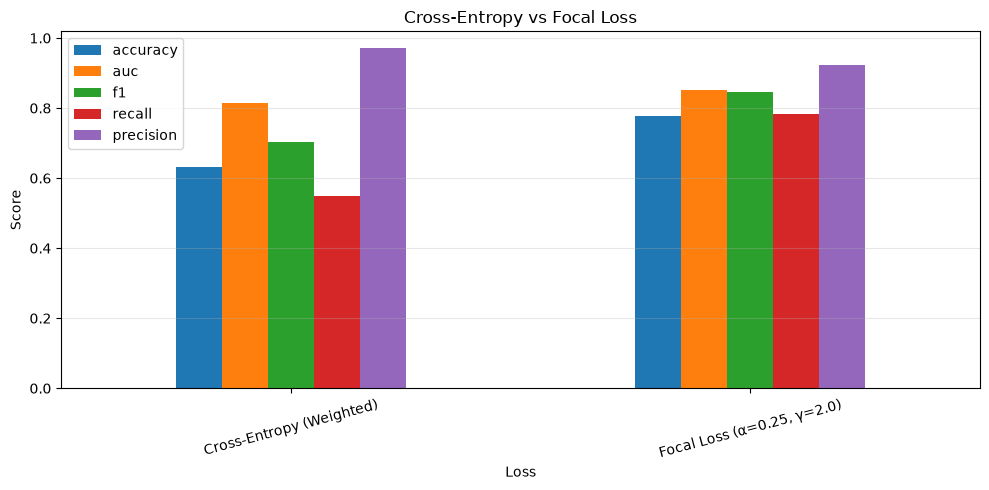


✅ Saved to results\loss_comparison.csv


In [20]:
# ==================== CELL 7 (FASTEST FIX): CE Only + Reuse Focal Loss ====================

# --- Cross-Entropy experiment ---
print("=" * 60)
print("EXPERIMENT: Cross-Entropy (Weighted)")
print("=" * 60)

torch.manual_seed(42)
np.random.seed(42)

ce_model = FusionModel(clinical_dim=clinical_dim).to(DEVICE)
ce_criterion = nn.CrossEntropyLoss(weight=weight_tensor)
ce_optimizer = optim.AdamW(ce_model.parameters(), lr=3e-4, weight_decay=1e-4)

best_auc, no_improve = -1.0, 0
best_state = None

for epoch in range(20):
    loss = train_epoch(ce_model, train_loader, ce_criterion, ce_optimizer, DEVICE)
    val_metrics = evaluate(ce_model, val_loader, DEVICE)
    print(f"Epoch {epoch+1:02d} | Loss: {loss:.4f} | Val AUC: {val_metrics['auc']:.4f}")
    if val_metrics["auc"] > best_auc:
        best_auc, no_improve = val_metrics["auc"], 0
        best_state = copy.deepcopy(ce_model.state_dict())
    else:
        no_improve += 1
        if no_improve >= 5:
            print(f"Early stopping at epoch {epoch+1}")
            break

ce_model.load_state_dict(best_state)
ce_metrics = evaluate(ce_model, test_loader, DEVICE)

print(f"\nCross-Entropy Test Metrics:")
for k, v in ce_metrics.items():
    print(f"  {k:10s}: {v:.4f}")


# --- Focal Loss: Reuse Notebook 05's proven result ---
print("\n" + "=" * 60)
print("FOCAL LOSS: Loading from Notebook 05 checkpoint")
print("=" * 60)

focal_model = FusionModel(clinical_dim=clinical_dim).to(DEVICE)
checkpoint = torch.load(MODEL_DIR / "best_fusion_model.pt", map_location=DEVICE)
focal_model.load_state_dict(checkpoint["model_state"])
focal_model.eval()
focal_metrics = evaluate(focal_model, test_loader, DEVICE)

print(f"Focal Loss Test Metrics:")
for k, v in focal_metrics.items():
    print(f"  {k:10s}: {v:.4f}")


# --- Save comparison ---
results = [
    {"Loss": "Cross-Entropy (Weighted)", **ce_metrics},
    {"Loss": "Focal Loss (α=0.25, γ=2.0)", **focal_metrics},
]
results_df = pd.DataFrame(results)
print("\n" + "=" * 68)
print("LOSS FUNCTION COMPARISON (Test Set)")
print("=" * 68)
print(results_df.round(4).to_string(index=False))
results_df.to_csv(RESULT_DIR / "loss_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
results_df.set_index("Loss")[["accuracy", "auc", "f1", "recall", "precision"]] \
    .plot(kind="bar", ax=ax, rot=15)
ax.set_title("Cross-Entropy vs Focal Loss")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "loss_comparison.png", dpi=200)
plt.show()

print(f"\n✅ Saved to {RESULT_DIR / 'loss_comparison.csv'}")

LOSS FUNCTION COMPARISON (Test Set)
                      Loss  accuracy    auc     f1  precision  recall
  Cross-Entropy (Weighted)    0.6316 0.8156 0.7021     0.9706  0.5500
Focal Loss (α=0.25, γ=2.0)    0.7763 0.8510 0.8468     0.9216  0.7833


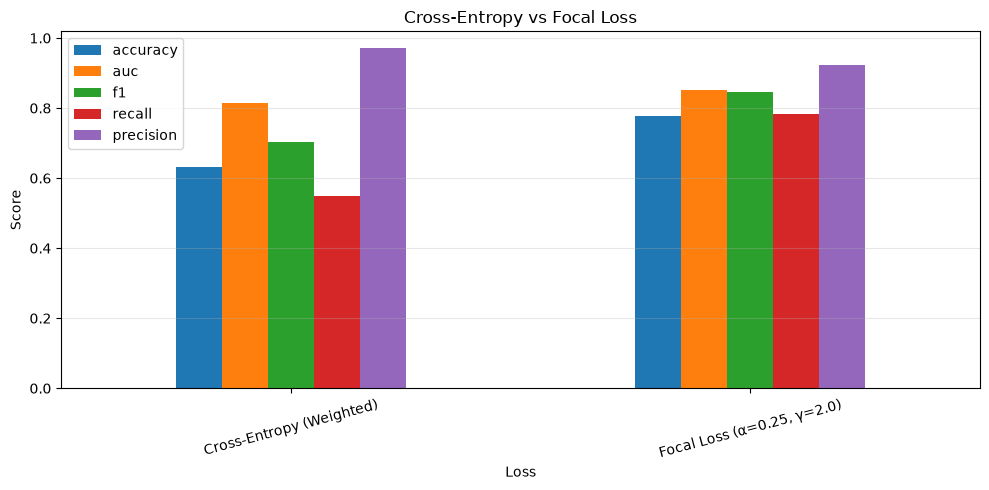

In [21]:
# ==================== CELL 8: Compare + Save ====================
results_df = pd.DataFrame(results)
print("LOSS FUNCTION COMPARISON (Test Set)")
print(results_df.round(4).to_string(index=False))
results_df.to_csv(RESULT_DIR / "loss_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
results_df.set_index("Loss")[["accuracy", "auc", "f1", "recall", "precision"]] \
    .plot(kind="bar", ax=ax, rot=15)
ax.set_title("Cross-Entropy vs Focal Loss")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "loss_comparison.png", dpi=200)
plt.show()